## Introduction

As a data analyst, your goal is to **evaluate how urban mobility relates to economic productivity in major Latin American cities**.
You will work with real data from the TomTom Traffic Index and OECD Cities, which you will clean, combine, and analyze to identify the cities where investment in transportation infrastructure may be most beneficial.


## 🧩 Step 1: Load and explore the data

Before cleaning or combining the data, it is necessary to **become familiar with the structure of both datasets**.
At this stage, you will verify that the files load correctly, review their columns and data types, and identify possible inconsistencies.

### 1.1 Load the data and perform a quick review

**🎯 Objective:**
Import the required libraries, load the CSV files into DataFrames, and perform a preliminary review to understand their contents.

**Instructions:**
- Import the `pandas`, `numpy`, `seaborn`, and `matplotlib.pyplot` libraries.
- Load the files using `pd.read_csv()`:
  - `'/datasets/tomtom_traffic.csv'`
  - `'/datasets/oecd_city_economy.csv'`
- Store the DataFrames in the variables `traffic` and `eco`.
- Display the first five rows of each DataFrame.


In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Load files
traffic = pd.read_csv('/datasets/tomtom_traffic.csv')
eco = pd.read_csv('/datasets/oecd_city_economy.csv')

In [ ]:
# Show the first 5 rows of traffic
traffic.head(5)

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232
3,ARE,abu-dhabi,2025-01-13 01:46:30.001,8.2,2.0,4.1,2.0,2.0,2025-01-06 01:46:30.000,7.723808,7.899046,-0.175238
4,ARE,abu-dhabi,2025-01-13 00:01:30.000,1.1,1.0,0.2,1.0,1.0,2025-01-06 00:01:30.000,8.336363,8.604379,-0.268016


In [ ]:
# Show the first 5 rows of eco
eco.head(5)

,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"
3,2023,brasilia,Brazil,"15.999,00",8.3%,"13,50","4,70"
4,2023,salvador,Brazil,"8.761,00",13.1%,"16,00","3,90"


**Tip:** The table will display more clearly if you do not use `print()`.

---

## 🧩 Step 2: Explore, clean, and prepare the data

Before combining the datasets, inspect their structure, data types, columns, and missing values.
Record the columns that require cleaning and then standardize the column names.

### 2.1 Explore the structure and data types

**🎯 Objective:**
Identify columns with incorrect data types, review distributions and missing values, and note the columns that require conversion.

**Instructions:**
- Use `.info()` to review the structure of both DataFrames.
- Display the first three rows of each DataFrame.
- Determine whether the structure of each DataFrame is correct or requires changes, and write your conclusions in the Markdown cell.
  - Are there columns that require conversion? Which ones? What are their current data types, and what should they be?
  - Are there missing values in any column?


In [ ]:
# Examine the traffic structure
traffic.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  object 
 1   City                            1004464 non-null  object 
 2   UpdateTimeUTC                   1004464 non-null  object 
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  object 
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  float64
dtype

The following issues were identified in the `traffic` DataFrame:
- `UpdateTimeUTC` and `UpdateTimeUTCWeekAgo` are stored as `float64` but should be converted to `datetime`.
- `JamsCount` is stored as `float` but should be converted to `integer`.


In [ ]:
# Examine the eco structure
eco.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Year             30 non-null     int64 
 1   City             30 non-null     object
 2   Country          30 non-null     object
 3   City GDP/capita  30 non-null     object
 4   Unemployment %   30 non-null     object
 5   PM2.5 (μg/m³)    30 non-null     object
 6   Population (M)   30 non-null     object
dtypes: int64(1), object(6)
memory usage: 1.8+ KB


The following issues were identified in the `eco` DataFrame:
- `City GDP/capita`, `Unemployment %`, `PM2.5 (μg/m³)`, and `Population (M)` are stored as `object` but should be converted to `float`.


### 2.2 Rename columns

**🎯 Objective:**
Standardize column names to prevent errors and facilitate the integration of the datasets.

**Instructions:**
- Rename the columns using `snake_case`.
  - `Country` → `country`
  - `UpdateTimeUTC` → `update_time_utc`
- Verify that the changes were applied correctly using `.columns`.


In [ ]:
# Standardize the traffic column names
# Add your code here
traffic = traffic.rename(columns= {
    'Country': 'country',
    'City': 'city',
    'UpdateTimeUTC': 'update_time_utc',
    'JamsDelay': 'jams_delay',
    'TrafficIndexLive': 'traffic_index_live',
    'JamsLengthInKms': 'jams_length_in_kms',
    'JamsCount': 'jams_count',
    'TrafficIndexWeekAgo': 'traffic_index_week_ago',
    'UpdateTimeUTCWeekAgo': 'update_time_utc_week_ago',
    'TravelTimeLivePer10KmsMins': 'travel_time_live_per_10_kms_mins',
    'TravelTimeHistoricPer10KmsMins': 'travel_time_historic_per_10_kms_mins',
    'MinsDelay': 'mins_delay'})

# Verify the changes
traffic.columns

Index(['country', 'city', 'update_time_utc', 'jams_delay',
       'traffic_index_live', 'jams_length_in_kms', 'jams_count',
       'traffic_index_week_ago', 'update_time_utc_week_ago',
       'travel_time_live_per_10_kms_mins',
       'travel_time_historic_per_10_kms_mins', 'mins_delay'],
      dtype='object')

In [ ]:
# Standardize the eco column names
# Add your code here
eco = eco.rename(columns= {
    'Year': 'year',
    'City': 'city',
    'Country': 'country',
    'City GDP/capita': 'city_gdp_per_capita',
    'Unemployment %': 'unemployment_pct',
    'PM2.5 (μg/m³)': 'pm2_5_ug_per_m3',
    'Population (M)': 'population_m'
} )

# Verify the changes
eco.columns

Index(['year', 'city', 'country', 'city_gdp_per_capita', 'unemployment_pct',
       'pm2_5_ug_per_m3', 'population_m'],
      dtype='object')

### 2.3 Correct numeric and date formats

**🎯 Objective:**
Ensure that date and numeric columns use the correct formats so that analyses, calculations, and comparisons can be performed accurately.

**Instructions:**
- Convert the date columns in `traffic` to `datetime`, using error handling.
- In the `eco` dataset, clean the numeric values:
  - In `city_gdp_per_capita`, remove thousands separators (`.`) and replace commas (`','`) with periods (`'.'`) before converting the column to `float`.
  - In `unemployment_pct`, remove the percent symbol (`%`) and replace commas (`','`) with periods (`'.'`) before converting the column to `float`.
  - In `population_m`, replace commas (`','`) with periods (`'.'`) before converting the column to `float`.
- Finally, create a new column named `population` by multiplying `population_m` by 1,000,000 to obtain the total population.


<details>
<summary>Click to view the hint</summary>

To remove symbols, replace them with an empty string.


In [ ]:
# Convert the traffic columns to datetime using pd.to_datetime()
traffic['update_time_utc'] = pd.to_datetime(traffic['update_time_utc'], errors='ignore') # Add your code here
traffic['update_time_utc_week_ago'] = pd.to_datetime(traffic['update_time_utc_week_ago'], errors='ignore') # Add your code here

# Verify the changes
traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                                Non-Null Count    Dtype         
---  ------                                --------------    -----         
 0   country                               1004464 non-null  object        
 1   city                                  1004464 non-null  object        
 2   update_time_utc                       1004464 non-null  datetime64[ns]
 3   jams_delay                            1004464 non-null  float64       
 4   traffic_index_live                    1004464 non-null  float64       
 5   jams_length_in_kms                    1004464 non-null  float64       
 6   jams_count                            1004464 non-null  float64       
 7   traffic_index_week_ago                1004464 non-null  float64       
 8   update_time_utc_week_ago              1004464 non-null  datetime64[ns]
 9   travel_time_live_per_10_kms_mins      1004464 

In [ ]:
# Remove separators and convert numeric columns in eco
eco['city_gdp_per_capita'] = eco['city_gdp_per_capita'].astype(str).str.replace('.', '').str.replace(',', '.').astype(float)
eco['unemployment_pct'] = eco['unemployment_pct'].astype(str).str.replace('%', '').str.replace(',', '.').astype(float)
eco['population_m'] = eco['population_m'].astype(str).str.replace(',', '.').astype(float)
# Calculate total population in absolute units (multiply by 1,000,000)
eco['population'] = eco['population_m'] * 1000000

# Verify the changes
eco.info()
eco.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   year                 30 non-null     int64  
 1   city                 30 non-null     object 
 2   country              30 non-null     object 
 3   city_gdp_per_capita  30 non-null     float64
 4   unemployment_pct     30 non-null     float64
 5   pm2_5_ug_per_m3      30 non-null     object 
 6   population_m         30 non-null     float64
 7   population           30 non-null     float64
dtypes: float64(4), int64(1), object(3)
memory usage: 2.0+ KB


,year,city,country,city_gdp_per_capita,unemployment_pct,pm2_5_ug_per_m3,population_m,population
0,2023,buenos-aires,Argentina,15782.0,6.2,"15,2",15.3,15300000.0
1,2023,sao-paulo,Brazil,14475.0,9.1,"29,50",22.5,22500000.0
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,"19,10",13.6,13600000.0


---

## 🧩 Step 3: Extract the year and filter the data

Extracting the year makes it possible to filter the information and work only with the most recent and relevant period.

### 3.1 Create the year column and filter for 2024

**🎯 Objective:**
Identify the year of each record and retain only records from 2024.

**Instructions:**
- Since the `traffic` DataFrame does not contain a year column, use the `.dt.year` attribute on its date column to create a new column named `year`.
- Filter the rows where the year is **2024**.
- Use `.copy()` to create two new DataFrames, `traffic_2024` and `eco_2024`, to avoid modifying the original datasets.


In [ ]:
# Extract the year from update_time_utc
traffic['year'] = traffic['update_time_utc'].dt.year

# Verify the change
traffic.head(3)

,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10_kms_mins,travel_time_historic_per_10_kms_mins,mins_delay,year
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437,2025
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635,2025
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232,2025


In [ ]:
# Filter records for 2024
traffic_2024 = traffic[traffic['year'] == 2024].copy()
eco_2024 = eco[eco['year'] == 2024].copy()

# Review the new DataFrames
display(traffic_2024.head())
display(eco_2024.head())


,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10_kms_mins,travel_time_historic_per_10_kms_mins,mins_delay,year
302,ARE,abu-dhabi,2024-12-31 23:01:30.000,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30.000,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30.000,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30.000,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30.000,11.456878,9.305174,2.151704,2024
305,ARE,abu-dhabi,2024-12-31 20:01:00.001,399.4,27.0,38.0,75.0,6.0,2024-12-24 20:01:30.001,11.670062,9.952811,1.717252,2024
306,ARE,abu-dhabi,2024-12-31 19:46:00.000,366.4,28.0,39.8,82.0,9.0,2024-12-24 19:01:00.000,11.686322,10.008469,1.677853,2024


,year,city,country,city_gdp_per_capita,unemployment_pct,pm2_5_ug_per_m3,population_m,population
15,2024,buenos-aires,Argentina,18117.0,7.2,"14,50",15.4,15400000.0
16,2024,sao-paulo,Brazil,14703.0,8.5,"28,00",22.6,22600000.0
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,"18,40",13.7,13700000.0
18,2024,brasilia,Brazil,16251.0,7.8,"12,80",4.8,4800000.0
19,2024,salvador,Brazil,8899.0,12.4,"15,20",3.9,3900000.0


---

## 🧩 Step 4: Analyze and summarize mobility data

The traffic dataset contains **multiple records per city**. In this section, you will calculate annual averages by city to simplify the analysis and obtain a clearer view of general trends.

### 4.1 Calculate average traffic metrics by city

**🎯 Objective:**
Create a consolidated view of average traffic by city and year to analyze general patterns without relying on daily observations.

**Instructions:**
- Group the data by `city`, `country`, and `year`.
- Calculate the mean only for the most relevant traffic metrics, including `jams_delay`, `traffic_index_live`, `jams_length_in_kms`, `jams_count`, `mins_delay`, `travel_time_live_per_10_kms_mins`, and `travel_time_historic_per_10_kms_mins`.
- Store the result in `traffic_city_year_2024`, keeping the grouping fields as columns rather than indexes.


<details>
<summary>Click to view the hint</summary>

Use `.agg()` to apply mean functions. Then reset the index so that the grouping fields remain as columns rather than indexes.


In [ ]:
# Calculate average traffic metrics by city, country, and year
traffic_city_year_2024 =  (traffic_2024
.groupby(['city', 'country', 'year'])
.agg({'jams_delay': 'mean', 'traffic_index_live': 'mean', 'jams_length_in_kms': 'mean', 'jams_count': 'mean', 'mins_delay': 'mean', 'travel_time_live_per_10_kms_mins': 'mean', 'travel_time_historic_per_10_kms_mins': 'mean'})
.reset_index())

# Display the result
traffic_city_year_2024.head()

,city,country,year,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,mins_delay,travel_time_live_per_10_kms_mins,travel_time_historic_per_10_kms_mins
0,a-coruna,ESP,2024,17.935187,15.259774,2.198002,4.934405,0.774172,16.267977,15.493804
1,aachen,DEU,2024,26.732141,20.960314,3.892586,6.601832,0.792968,13.397861,12.604894
2,aarhus,DNK,2024,21.200616,16.575891,2.736736,6.109987,0.495276,15.219292,14.724016
3,abu-dhabi,ARE,2024,171.157315,13.902028,24.507380,47.268019,0.139764,9.829092,9.689328
4,adana,TUR,2024,83.864761,22.541040,11.827331,23.754620,1.129749,15.879694,14.749945


### 🧠 Reflection

Excellent work so far.

Now that you have calculated annual averages by city, examine the results carefully.

Consider:

- Which city do you expect to have the highest average traffic delay?
- Will it be a city in **Europe**, **Latin America**, or **another region**?

To find out, run the following line of code:

`traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)`

🔍 Review the cities at the top of the table.

Are the results surprising? Do they match your expectations?


In [ ]:
# Add your code here
traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)

,city,country,year,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,mins_delay,travel_time_live_per_10_kms_mins,travel_time_historic_per_10_kms_mins
221,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,1.855542,21.809092,19.953550
352,tokyo,JPN,2024,2152.574357,36.805059,373.069734,518.809420,0.698152,22.443778,21.745626
246,new-york,USA,2024,2133.400000,28.210388,398.227892,544.474902,1.396351,18.505043,17.108691
200,london,GBR,2024,2050.703662,29.230166,287.632868,471.795554,1.325160,17.714139,16.388979
211,manila,PHL,2024,1741.493381,66.129402,246.858082,341.881205,2.469894,27.134629,24.664734
...,...,...,...,...,...,...,...,...,...,...
111,dunedin,NZL,2024,4.651175,15.430809,0.712315,1.591384,0.633294,16.226009,15.592715
363,uppsala,SWE,2024,4.194486,13.939168,0.656368,1.349672,0.501802,15.746717,15.244916
123,fujairah,ARE,2024,4.025959,10.907719,0.731910,1.373006,0.194951,11.662590,11.467639
12,almere,NLD,2024,3.633523,6.290478,0.506362,1.064063,-0.017544,9.467150,9.484694


Mexico City has the highest average traffic delay.

---

## 🧩 Step 5: Combine mobility and economic data

Combining datasets makes it possible to analyze how economic indicators relate to urban mobility.

### 5.1 Merge traffic data with economic indicators

**🎯 Objective:**
Combine traffic and economic information in a single DataFrame to analyze how economic conditions relate to urban mobility.

**Instructions:**
- Select only the **relevant columns** from each dataset.
- Use `.copy()` when creating subsets to avoid modifying the original datasets.
- Merge both DataFrames using `city` and `year` as the join keys.
- Retain only the cities and years that appear in both datasets.
- Store the result in a new variable named `merged` and display the first five rows.


<details>
<summary>Click to view the hint</summary>

Use an `inner` join to retain only the cities and years that are present in both datasets.


In [ ]:
# Select key traffic and economic columns
left_cols = ['city','country','year','jams_delay','traffic_index_live',
             'jams_length_in_kms','jams_count','mins_delay',
             'travel_time_live_per_10_kms_mins','travel_time_historic_per_10_kms_mins']

right_cols = ['city','year','city_gdp_per_capita','unemployment_pct','pm2_5_ug_per_m3','population_m']

# Use .copy() to create the two reduced datasets
traffic_2024_small = traffic_city_year_2024[left_cols].copy()
eco_2024_small = eco_2024[right_cols].copy()

# Merge the datasets
merged = traffic_2024_small.merge(eco_2024_small, on= ['city', 'year'], how='inner')
# Add your code here

# Display the first five rows
# Add your code here
merged.head(5)

,city,country,year,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,mins_delay,travel_time_live_per_10_kms_mins,travel_time_historic_per_10_kms_mins,city_gdp_per_capita,unemployment_pct,pm2_5_ug_per_m3,population_m
0,belo-horizonte,BRA,2024,263.047879,19.428946,44.038129,68.805422,0.487228,18.304538,17.817311,11124.0,9.5,"16,80",6.1
1,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,1.699628,24.992185,23.292557,11442.0,10.0,"17,60",11.3
2,brasilia,BRA,2024,101.576326,11.258220,18.337133,27.280140,0.193442,13.338658,13.145216,16251.0,7.8,"12,80",4.8
3,buenos-aires,ARG,2024,571.089593,17.756012,100.287844,137.359860,0.416566,17.907916,17.491349,18117.0,7.2,"14,50",15.4
4,curitiba,BRA,2024,183.469274,14.954545,30.050044,46.898164,0.139965,17.258700,17.118736,12381.0,8.2,"13,50",3.7


---

## 🧩 Step 6: Visualize and analyze relationships

Now that you have a clean and integrated dataset, it is time to **visualize patterns**.
The charts will help explain how economic variables relate to urban mobility.

### 6.1 Visualize relationships between the economy and traffic

**🎯 Objective:**
Visually analyze the distribution and relationship between traffic and economic indicators in 2024 to identify possible patterns or general trends.

**Instructions:**
- Use `seaborn` and `matplotlib.pyplot` to generate the charts.
- Visualize the distribution of traffic (`jams_delay`) with:
  - A **boxplot** to observe the mean, median, and potential outliers.
- Visualize the distribution of the economy (`city_gdp_per_capita`) with:
  - A **histogram** to analyze the shape of the distribution and the average GDP per capita.
- Finally, compare both variables in a single bar chart.
- Add a title and axis labels to each chart.
- Describe the patterns, extreme values, and possible relationships that you identify.


**Tip:** Add `showmeans=True` inside the boxplot parentheses to display the mean.

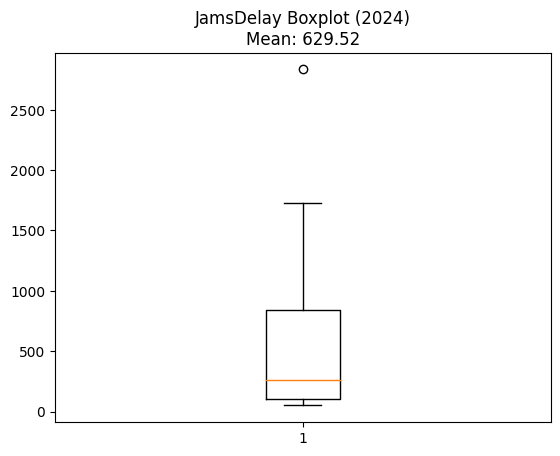

In [ ]:
# Create a boxplot to examine the distribution of JamsDelay
# Create the chart
plt.boxplot(merged['jams_delay'])

# Calculate the mean to display it in the title
mean_value = merged['jams_delay'].mean()
plt.title(f'JamsDelay Boxplot (2024)\nMean: {mean_value:.2f}')
plt.show()


<AxesSubplot:xlabel='city_gdp_per_capita', ylabel='Count'>

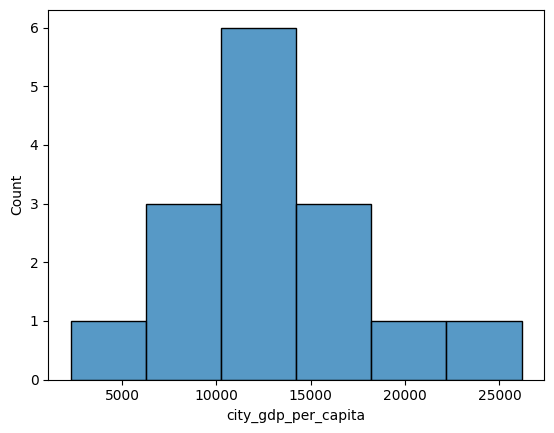

In [ ]:
# Create a histogram to examine the distribution of city_gdp_per_capita
sns.histplot(merged['city_gdp_per_capita'])

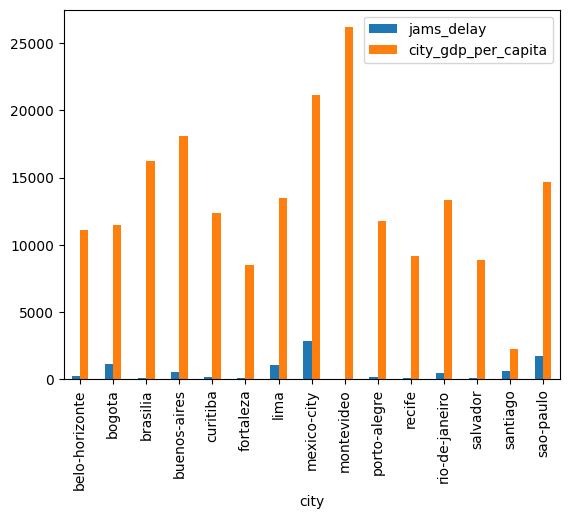

In [ ]:
# Create a bar chart to compare jams_delay and city_gdp_per_capita by city
merged.plot(kind='bar' , x='city', y=['jams_delay', 'city_gdp_per_capita'])

plt.xticks(rotation=90)
plt.show()

**Tip:** Add `plt.xticks(rotation=90)` before `plt.show()` to rotate the x-axis labels by 90 degrees.

### 🧠 Reflection

Excellent work reaching this stage of the analysis. Before continuing, review the charts and consider:

- Do cities with higher GDP per capita also experience greater congestion?
- Does the opposite occur, or is there no clear relationship?


Write your comments:

There is no clear relationship between higher GDP per capita and average congestion levels.

Mexico City has the highest congestion level and the second-highest GDP per capita in the region, whereas Montevideo has the highest GDP per capita and one of the lowest congestion values.


In [ ]:
merged[['city', 'year', 'country']].nunique()

city       15
year        1
country     7
dtype: int64

In [ ]:
print("Number of cities:", merged['city'].nunique())
print("Years:", merged['year'].unique())
print("Number of countries:", merged['country'].nunique())
print("Countries:", merged['country'].sort_values().unique())

Number of cities: 15
Years: [2024]
Number of countries: 7
Countries: ['ARG' 'BRA' 'CHL' 'COL' 'MEX' 'PER' 'URY']


---

## 🧩 Step 7: Export and document the results

In this final stage, you will consolidate your work by saving the clean dataset and preparing a summary of the project results.

### 7.1 Save the final dataset

**🎯 Objective:**
Generate a clean and reproducible CSV file containing the relevant columns for future analysis.

**Instructions:**
- Export the `merged` DataFrame using the filename `ladb_mobility_economy_2024_clean.csv`.
- Use `index=False` to exclude the index.


In [ ]:
# Export the final dataset as CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)

To view or download the generated file, use the left-hand menu and scroll to the **Export dataset** section for additional information.

---

## ✅ Deliverables

1. A `.ipynb` notebook containing all cells, including code and comments.
2. The final CSV file: `ladb_mobility_economy_2024_clean.csv`.
3. A brief executive summary in Markdown consisting of three to five paragraphs.


# 🧾 Executive Summary

### Context & Objective:

No direct relationship was observed between higher GDP per capita and more congested urban mobility.

In 2024, cities such as Montevideo, Brasília, and Rio de Janeiro recorded GDP per capita values of 26,176, 16,251, and 13,349, respectively, all above the median of 12,381. However, their average total congestion delay, calculated from the measurements collected throughout 2024 across all monitored roads, was 50.20, 101.57, and 466.06 minutes, respectively; in all three cases, below the overall average of 629.51 minutes.

These results suggest that higher GDP per capita is not necessarily associated with higher levels of urban congestion.

The key variables used were jams_delay, from the traffic table, and city_gdp_per_capita and population_m, from the economic table.

jams_delay represents the total delay caused by congestion on monitored roads and was calculated as an average by city for 2024. This variable helps identify the cities with the most severe mobility problems and supports decisions related to transportation and infrastructure.

GDP per capita represents the level of economic output per resident and allows economic productivity to be compared across cities. Its integration with mobility data helps evaluate whether cities with higher productivity also experience higher levels of congestion.

The population_m variable represents the total population of each city, expressed in millions of residents. Its inclusion makes it possible to analyze the extent to which population size relates to delays, congestion length, and the number of traffic jams.

### Data Coverage:

The analysis used 2024 data from 15 cities located in seven countries: Argentina, Brazil, Chile, Colombia, Mexico, Peru, and Uruguay.

### Methodology (High Level):

The structures of the traffic and eco tables were analyzed, and their data types were adjusted according to the descriptions of their variables. Column names were then standardized to prevent errors and facilitate dataset integration. Numeric and date formats were also corrected to support accurate calculations and comparisons. Finally, both tables were filtered to include only 2024 data.

Traffic indicators were grouped by city and year, and their average values, including jams_delay, were calculated. The relevant variables from the traffic and economic tables were then selected and integrated through an INNER join using city and year as keys.

This type of join retained only the 2024 cities with matching information in both datasets, making it possible to compare their mobility conditions with their economic indicators.

To identify distributions, outliers, and possible trends between traffic and economic variables, the seaborn and matplotlib.pyplot libraries were used. A boxplot of jams_delay, a histogram of city_gdp_per_capita, and combined charts comparing both variables were generated.

The boxplot showed that approximately the central 50% of cities had jams_delay values between 100 and 850 minutes. It also identified an outlier near 2,833 minutes corresponding to Mexico City. The mean was 629.52 minutes, while the median was close to 275 minutes.

The histogram indicated that most cities were concentrated within an approximate GDP per capita range of USD 10,000 to USD 14,000. It also showed a rightward extension caused by a small number of cities with higher values, close to USD 20,000–26,000.

Finally, the visual comparison of both variables did not reveal a clear relationship between higher GDP per capita and a higher average level of urban congestion.

### Initial Findings:

Overall, no direct relationship was observed between the traffic index and GDP per capita. For example, Montevideo and Brasília recorded relatively high GDP per capita values but low accumulated delays and lower traffic indexes. In contrast, Mexico City also had a high GDP per capita but recorded the greatest delays, the longest congestion length, and the largest number of traffic jams in the dataset. This suggests that economic development, measured through GDP per capita, does not by itself explain the observed congestion levels, since traffic also depends on factors such as infrastructure, urban planning, public transportation availability, and population size.

By contrast, total population showed a positive association with several traffic indicators. Cities such as Mexico City and São Paulo, each with more than 22 million residents, recorded high levels of delay, congestion length, and number of traffic jams. Bogotá and Lima also presented high traffic indicators with populations above 11 million. However, the relationship was not uniform: Buenos Aires, with 15.4 million residents, recorded more moderate congestion levels than Mexico City or São Paulo. This indicates that, in addition to population size, factors such as urban distribution, road capacity, and public transportation efficiency play an important role in mobility patterns.

Buenos Aires represents a case that warrants deeper analysis because, despite having the third-highest GDP per capita and the third-largest population in the dataset, it recorded significantly lower congestion levels than Mexico City, São Paulo, Bogotá, or Lima. This pattern reinforces the idea that GDP per capita and population size, although related to mobility patterns, are not sufficient on their own to explain differences in urban traffic. Factors such as road infrastructure, urban planning, and public transportation efficiency may also play a determining role.

### Recommendations

Bogotá is the city that best meets the stated criteria. It recorded the highest traffic index in the dataset (37.6), while its GDP per capita (11,442) was below the sample average (13,253). It also has a population of 11.3 million residents, the fifth largest among the cities analyzed. This combination of high vehicular congestion, below-average economic productivity, and a significant population suggests that Bogotá could be considered a priority city for transportation infrastructure investment, with the potential to improve mobility and contribute to economic development.

